<a href="https://colab.research.google.com/github/ccchipsss/cpp-practice-2026/blob/main/HW5/Kim_Y_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [34]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // Источник: аргумент командной строки, иначе — URL по умолчанию
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    // Каскады
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    // Подготовка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц — вернёт ВСЕ найденные лица
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        /*scaleFactor*/  1.05,   // чуть меньше, чем 1.1 — ищем тщательнее (для групповых фото)
        /*minNeighbors*/ 5,
        /*flags*/        0,
        /*minSize*/      cv::Size(20, 20)   // маленькие лица тоже ловим
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;
    int total_eyes = 0;//добавила для глаз
    // Рисуем рамку + номер для каждого лица
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        // Подпись "Face N" над рамкой
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        // Глаза ищем только в верхних 60% лица (там они и находятся)
        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        total_eyes += eyes.size();//добавила для глаз
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected eyes: " << total_eyes << std::endl;//добавила для глаз
    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Overwriting detect_faces.cpp


In [35]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

In [41]:
from google.colab import files
uploaded = files.upload()

Saving arthas.jpg to arthas.jpg


In [43]:
!./detect_faces arthas.jpg

Loading: arthas.jpg
Image: 736x502
Detected faces: 3
Detected eyes: 4
Result saved: faces_detected.jpg


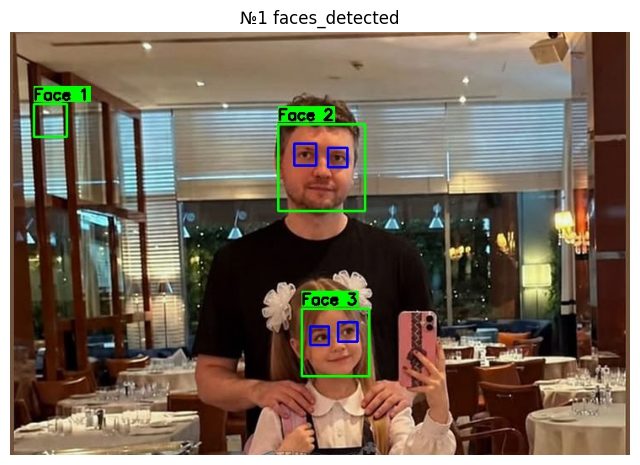

In [44]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('№1 faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

In [45]:
from google.colab import files
uploaded = files.upload()

Saving mi.jpg to mi.jpg


In [59]:
!./detect_faces mi.jpg

Loading: mi.jpg
Image: 1195x896
Detected faces: 8
Detected eyes: 6
Result saved: faces_detected.jpg


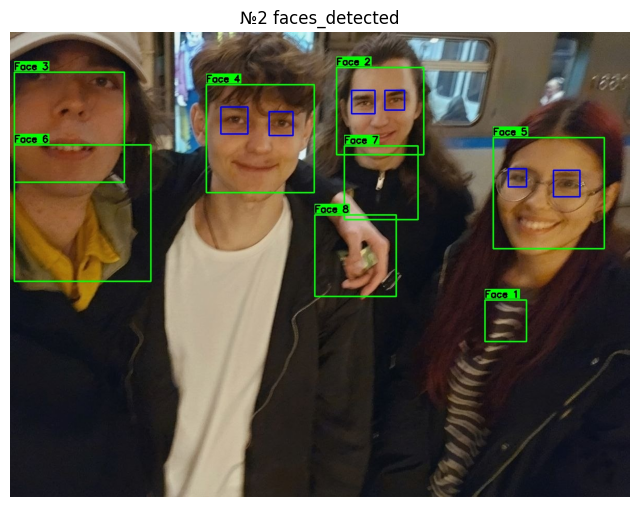

In [60]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('№2 faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

In [55]:
from google.colab import files
uploaded = files.upload()

Saving bog.jpg to bog.jpg


In [56]:
!./detect_faces bog.jpg

Loading: bog.jpg
Image: 736x982
Detected faces: 4
Detected eyes: 2
Result saved: faces_detected.jpg


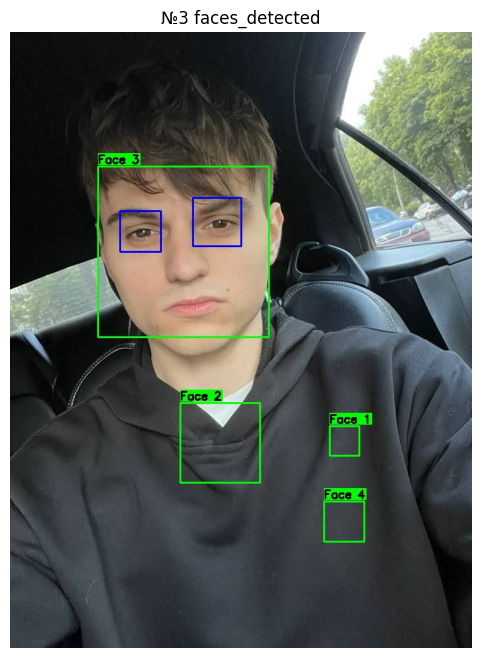

In [58]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('№3 faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

**Результаты**

**№1**
* Реально: 2 лица, 4 глаза
* Распознано: 3 лица, 4 глаза
* Итог - 1 ложное срабатывание на блик в левом верхнем углу.

**№2**
* Реально: 4 лица, 8 глаз
* Распознано: 8 лиц, 6 глаз
* Итог - ложные определения лиц (на одежде, руки, дробление 1 лица на несколько) и отсутвие обнаружения 1 пары глаз

**№3**
* Реально: 1 лицо, 2 глаза
* Распознано: 4 лица, 2 глаза
* Итог - ложные срабатывания лиц


*Вывод*

1. Принцип работы каскадов - алгоритм ищет не лицо целиком, а перепады яркости. Поэтому складки одежды, блики или руки часто принимаются за лица
2. Чувствительность к поворотам - при наклоне или повороте головы алгоритм ломает одно лицо на несколько отдельных рамок.
3. Зависимость глаз от лица - детектор глаз работает только внутри найденной рамки лица. Если лицо найдено ошибочно или криво, глаза либо не находятся, либо определяются неверно
